# Single-Cell RNA-seq Analysis: Clustering and Differential Expression

Analysis of single-cell RNA-seq data using Python and Scanpy, focusing on
quality control, normalization, dimensionality reduction, unsupervised
clustering, clustering evaluation, and differential gene expression.

## Objectives

- Preprocess and quality-control single-cell RNA-seq data
- Normalize gene expression and identify highly variable genes
- Perform PCA-based dimensionality reduction
- Compare three clustering approaches
- Evaluate clustering using silhouette score, ARI, and NMI
- Visualize cell populations using UMAP and t-SNE
- Identify and interpret differentially expressed genes in selected clusters

## Tools

Python · Scanpy · pandas · NumPy · scikit-learn · Matplotlib

# 1. Preprocessing

## 1.1 Loading the expression matrix and metadata
The expression matrix and cell-level metadata are loaded and combined
into an AnnData object for downstream analysis with Scanpy.

The notebook extracts `data/single_cell_dataset.zip` automatically and locates the expression matrix and metadata files within the extracted archive.


In [ ]:
import scanpy as sc
import pandas as pd

In [ ]:
from pathlib import Path
import zipfile

# Expected repository layout:
# data/single_cell_dataset.zip
DATA_DIR = Path("data")
ZIP_PATH = DATA_DIR / "single_cell_dataset.zip"
EXTRACT_DIR = DATA_DIR / "extracted"

if not ZIP_PATH.is_file():
    raise FileNotFoundError(
        f"Dataset archive not found: {ZIP_PATH}. "
        "Place single_cell_dataset.zip inside the repository's data/ folder."
    )

EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

# Extract safely (reject archive entries that would write outside EXTRACT_DIR).
with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    destination = EXTRACT_DIR.resolve()
    for member in archive.infolist():
        target = (EXTRACT_DIR / member.filename).resolve()
        if target != destination and destination not in target.parents:
            raise ValueError(f"Unsafe path in dataset archive: {member.filename}")
    archive.extractall(EXTRACT_DIR)

# Find the two input files even if the ZIP contains a parent directory.
expr_matches = list(EXTRACT_DIR.rglob("ABC_umi_matrix_7551_cells.csv"))
meta_matches = list(EXTRACT_DIR.rglob("ABC_Meta.txt"))
if len(expr_matches) != 1 or len(meta_matches) != 1:
    raise FileNotFoundError(
        "Expected exactly one ABC_umi_matrix_7551_cells.csv and one "
        "ABC_Meta.txt inside the ZIP archive. Check the archive contents."
    )

EXPR_PATH = expr_matches[0]
META_PATH = meta_matches[0]
print(f"Expression matrix: {EXPR_PATH}")
print(f"Cell metadata: {META_PATH}")


In [ ]:
expr = pd.read_csv(
   EXPR_PATH,
    index_col=0
)

In [ ]:
meta = pd.read_csv(
    META_PATH,
    sep="\t",
    index_col=0
)


In [ ]:
# Only keep cells that appear in both files
common_cells = expr.index.intersection(meta.index)

expr = expr.loc[common_cells]
meta = meta.loc[common_cells]


In [ ]:
# Create AnnData object which is used by scanpy
adata = sc.AnnData(
    X=expr.values,
    obs=meta,
    var=pd.DataFrame(index=expr.columns)
)


adata.obs_names = expr.index
adata.var_names = expr.columns


## 1.2 Quality Control

Quality-control metrics are calculated at the cell level to identify
low-quality cells and potential outliers before downstream analysis.

In [ ]:
# Genes that start with "MT-" are flagged as mitochondrial.

adata.var["mt"] = adata.var_names.str.startswith("MT-")

For each cell, we calculate the number of detected genes, total UMI
counts, and the proportion of reads originating from mitochondrial genes.
These metrics are used to assess cell quality.

In [47]:
# calculate UMI count, and the number of genes detected
sc.pp.calculate_qc_metrics(
    adata,
    qc_vars=["mt"],
    percent_top=None,
    log1p=False,
    inplace=True
)


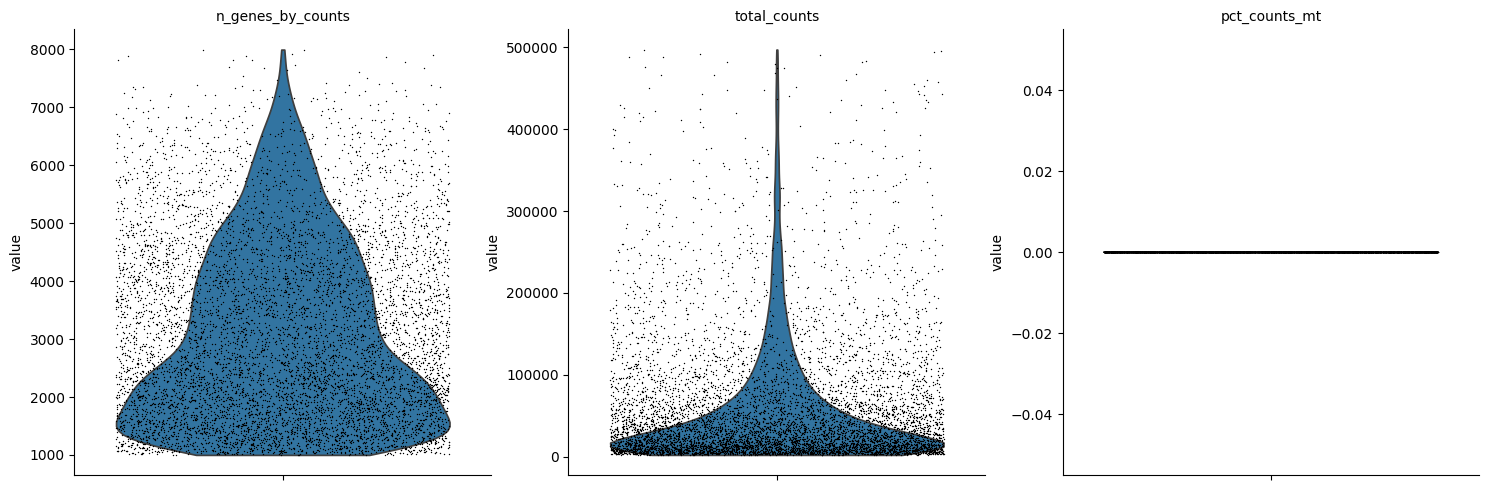

In [48]:
# violin plot for the calculated metrics
sc.pl.violin(
    adata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.4,
    multi_panel=True
)


The mitochondrial fraction is zero across the dataset, indicating that
no genes matching the `MT-` naming pattern were detected in the input
matrix. Therefore, mitochondrial-content filtering was not informative
for this dataset.

### Cell filtering

Cells were retained if they had:

- >1,000 and <7,000 detected genes
- >2,000 and <200,000 total UMI counts

These thresholds were used to remove cells with unusually low or high
library complexity.

In [ ]:
adata = adata[
    (adata.obs["n_genes_by_counts"] > 1000) &
    (adata.obs["n_genes_by_counts"] < 7000) &
    (adata.obs["total_counts"] > 2000) &
    (adata.obs["total_counts"] < 200000),
    :
]

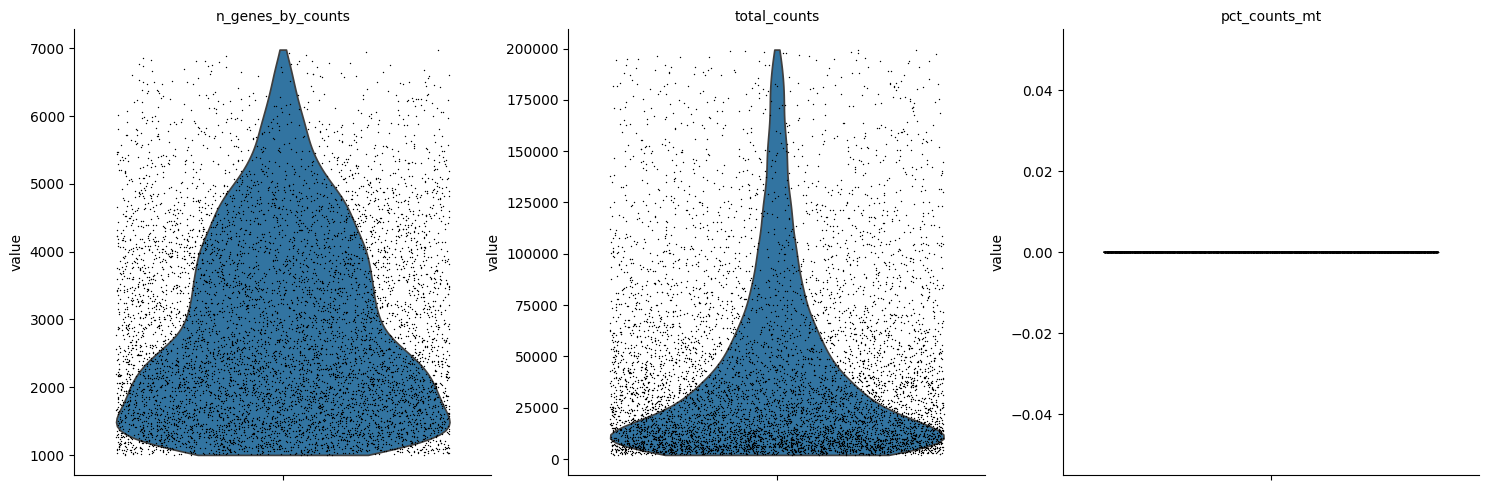

In [50]:
# violin plot after filtering
sc.pl.violin(
    adata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.4,
    multi_panel=True
)


In [ ]:
print(f"Cells before QC: {expr.shape[0]}")
print(f"Cells after QC: {adata.n_obs}")

After filtering, 7,070 cells remained for downstream analysis (the sum of the spectral cluster sizes shown in Section 3.1).

## 1.3 Normalization

### Library-size normalization and log transformation

Counts are normalized to a common library size of 10,000 counts per
cell and then log-transformed using `log1p`.

The normalized expression matrix is stored in `adata.raw` so that the
normalized values remain available for downstream interpretation.

In [ ]:
# Normalize
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata.copy()

### Gene filtering and highly variable genes

Genes detected in fewer than 10 cells are removed to reduce the influence
of sparsely detected genes.

The 2,000 most highly variable genes are then selected using the Seurat
method. These genes are used for downstream dimensionality reduction
and clustering.

In [ ]:
sc.pp.filter_genes(adata, min_cells=10)
sc.pp.highly_variable_genes(adata, flavor="seurat", n_top_genes=2000)
adata = adata[:, adata.var.highly_variable]


### Scaling

Highly variable genes are standardized to zero mean and unit variance.
Values are clipped at ±10 to reduce the influence of extreme values
before PCA.

In [ ]:
sc.pp.scale(adata, max_value=10)

# 2. Clustering Analysis

## 2.1 PCA and Unsupervised Clustering

### Principal Component Analysis

PCA is applied to the scaled highly variable genes to reduce the
dimensionality of the expression matrix before clustering.

The first 30 principal components are used as the feature space for
the clustering algorithms.

In [ ]:
sc.tl.pca(adata, svd_solver="arpack")

n_pcs = 30
X_pca = adata.obsm["X_pca"][:, :n_pcs]



### Unsupervised clustering

Three clustering approaches were applied to the PCA representation:

1. K-means clustering
2. Agglomerative hierarchical clustering
3. Spectral clustering

All methods were configured to produce 15 clusters to allow direct
comparison between approaches.


In [55]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=15,
    random_state=42
)

adata.obs["kmeans"] = kmeans.fit_predict(X_pca).astype(str)


In [56]:
from sklearn.cluster import AgglomerativeClustering

hier = AgglomerativeClustering(
    n_clusters=15,
    linkage="ward"
)

adata.obs["hierarchical"] = hier.fit_predict(X_pca).astype(str)


In [57]:
from sklearn.cluster import SpectralClustering

spectral = SpectralClustering(
    n_clusters=15,
    affinity="nearest_neighbors",
    n_neighbors=15,
    random_state=42
)

adata.obs["spectral"] = spectral.fit_predict(X_pca).astype(str)

## 2.2: Model Evaluation

### Clustering evaluation

Clustering results are evaluated using three complementary metrics:

- **Silhouette score:** measures separation and cohesion of clusters in PCA space.
- **Adjusted Rand Index (ARI):** measures agreement between clustering labels
  and the reference annotations, adjusted for chance.
- **Normalized Mutual Information (NMI):** measures the information shared
  between clustering labels and the reference annotations.

Higher values indicate greater agreement or separation for these metrics,
although each metric captures a different property of clustering quality.

In [ ]:
from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)

# Convert labels
reference_labels = adata.obs["redefined_cluster"].astype("category").cat.codes

kmeans_labels = adata.obs["kmeans"].astype(int)
hier_labels = adata.obs["hierarchical"].astype(int)
spec_labels = adata.obs["spectral"].astype(int)

# Silhouette
sil_kmeans = silhouette_score(X_pca, kmeans_labels)
sil_hier = silhouette_score(X_pca, hier_labels)
sil_spec = silhouette_score(X_pca, spec_labels)

# ARI
ari_kmeans = adjusted_rand_score(reference_labels, kmeans_labels)
ari_hier = adjusted_rand_score(reference_labels, hier_labels)
ari_spec = adjusted_rand_score(reference_labels, spec_labels)

# NMI
nmi_kmeans = normalized_mutual_info_score(reference_labels, kmeans_labels)
nmi_hier = normalized_mutual_info_score(reference_labels, hier_labels)
nmi_spec = normalized_mutual_info_score(reference_labels, spec_labels)

In [ ]:
# model evaluation results
import pandas as pd

results = pd.DataFrame({
    "Method": ["K-means", "Hierarchical", "Spectral"],
    "Silhouette": [sil_kmeans, sil_hier, sil_spec],
    "ARI": [ari_kmeans, ari_hier, ari_spec],
    "NMI": [nmi_kmeans, nmi_hier, nmi_spec]
})

results.round(3)


,Method,Silhouette,ARI,NMI
0,K-means,0.329752,0.298164,0.650088
1,Hierarchical,0.305338,0.261964,0.636494
2,spectral,0.311585,0.309465,0.655126


### Interpretation

The three methods gave similar results, with small differences across the metrics. Spectral clustering had the highest ARI (0.309) and NMI (0.655), meaning the closest agreement with the reference cell-type annotations, whereas K-means had the highest silhouette score (0.330). The silhouette score measures compactness and separation in PCA space, which favors the compact clusters that K-means optimizes, so it does not necessarily reflect biological agreement.

Because the differences are small (ARI 0.262-0.309, NMI 0.636-0.655) and come from a single run with a fixed random seed, they should not be over-interpreted. Spectral clustering was selected for the downstream analysis because of its slightly higher agreement with the reference annotations.

## 2.3: Dimensionality Reduction and Visualization

The selected Spectral clustering method is used to investigate the
distribution of the inferred cell populations in a low-dimensional space.
A k-nearest-neighbor graph is constructed from the first 30 principal
components. UMAP and t-SNE are then used to visualize the cells in two dimensions.

The results are compared using both the reference cell-type
annotations and the Spectral clustering labels.

In [61]:
sc.pp.neighbors(
    adata,
    n_neighbors=15,
    n_pcs=30
)


In [62]:
sc.tl.umap(adata)


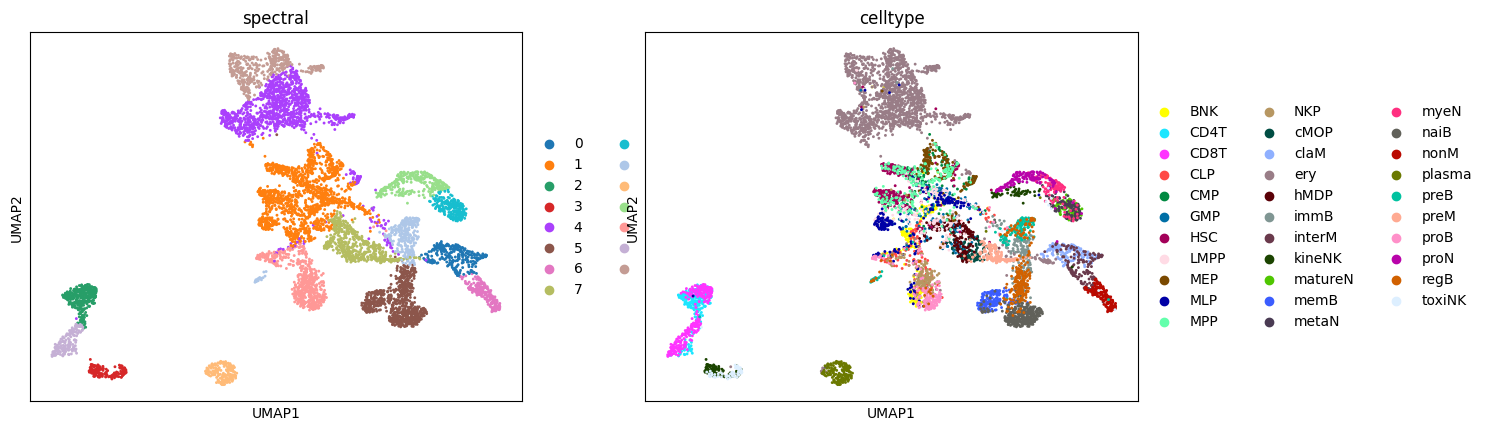

In [63]:
sc.pl.umap(
    adata,
    color=["spectral", "celltype"],

)


In [64]:
sc.tl.tsne(
    adata,
    n_pcs=30,
    perplexity=30,
    random_state=42
)

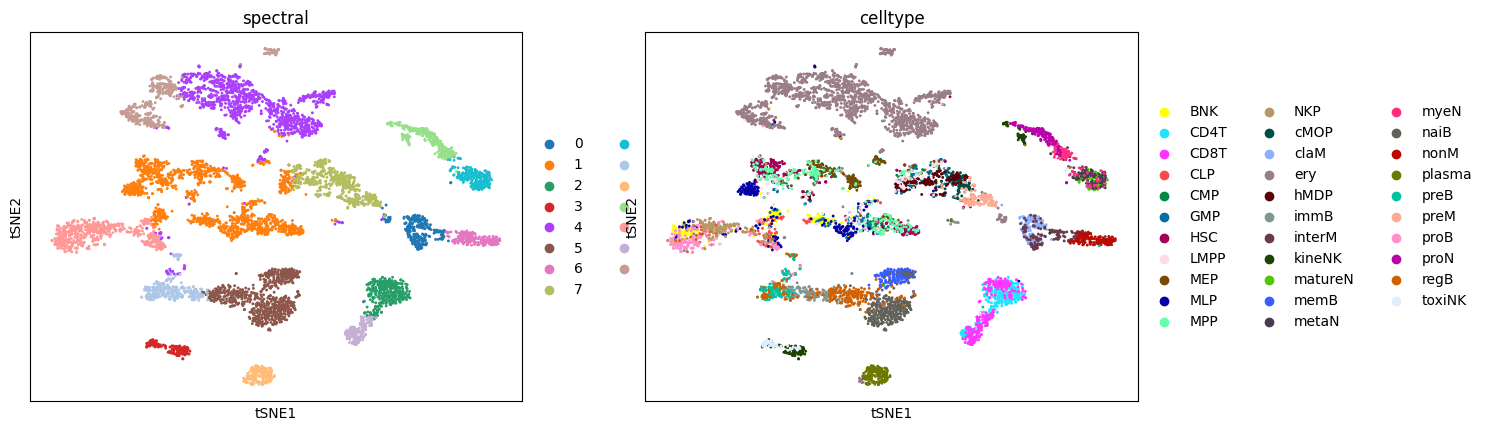

In [65]:
sc.pl.tsne(
    adata,
    color=["spectral", "celltype"],
    ncols=2
)

### UMAP and t-SNE interpretation

Both t-SNE and UMAP show clearly structured cell distributions, indicating that the dominant sources of variation in the data are biologically meaningful. When colored by spectral clustering labels, well-defined clusters are observed, suggesting that the clustering algorithm successfully partitions cells based on similarity.

Comparison with known cell type annotations shows that major immune cell types, including B cells and T cells, are divided into compact and well-separated clusters, reflecting strong transcriptional differences between mature immune cell types.

In contrast, hematopoietic progenitor cells such as HSCs, MPPs, CMPs, GMPs, and MEPs partially overlap and form continuous regions rather than separated clusters. This pattern is consistent with their biology, where progenitor cells share overlapping gene expression programs.

# 3. Differential Expression Analysis

## 3.1 Selection of clusters for differential expression

Cluster sizes were examined first to avoid selecting extremely small
clusters for downstream differential expression analysis.

In [66]:
adata.obs["spectral"].value_counts()


spectral
1     1395
4     1198
5      747
12     590
7      537
14     427
2      340
9      308
11     296
0      292
8      226
6      202
10     179
13     179
3      154
Name: count, dtype: int64

Cluster composition was examined using the available cell-type
annotations to assess the biological composition of each spectral
cluster before selecting clusters for differential expression analysis.

In [67]:
import pandas as pd

pd.crosstab(
    adata.obs["spectral"],
    adata.obs["celltype"]
)

celltype,BNK,CD4T,CD8T,CLP,CMP,GMP,HSC,LMPP,MEP,MLP,...,myeN,naiB,nonM,plasma,preB,preM,proB,proN,regB,toxiNK
spectral,,,,,,,,,,,,,,,,,,,,,
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
1,130,0,0,33,146,133,243,154,130,164,...,0,2,0,1,0,0,0,0,0,1
2,0,203,134,0,0,0,0,0,0,1,...,0,0,0,0,1,0,0,0,0,1
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,58
4,5,0,1,8,11,0,4,1,20,6,...,0,0,0,0,9,0,3,0,1,0
5,0,0,0,0,0,0,0,0,0,0,...,0,341,0,0,2,0,0,0,171,0
6,0,0,0,0,0,0,0,0,0,0,...,0,0,156,0,1,0,0,0,0,2
7,0,0,0,3,6,51,3,46,9,1,...,0,0,0,0,0,149,0,0,0,0
8,0,0,0,0,0,0,0,0,0,0,...,27,0,0,0,0,0,0,4,0,4


### Selected clusters

Based on cluster size and cell-type composition, three clusters were
selected for further investigation:

- **Cluster 2:** predominantly CD8+ and CD4+ T cells
- **Cluster 5:** predominantly naive and regulatory B cells
- **Cluster 10:** predominantly plasma cells

In [68]:
#Converting cluster labels into a categorical variable
adata.obs["spectral"] = adata.obs["spectral"].astype("category")

For each selected cluster, gene expression was compared with all
remaining cells using the Wilcoxon rank-sum test.

In [ ]:
# Differential expression: selected cluster vs. all remaining cells
sc.tl.rank_genes_groups(
    adata,
    groupby="spectral",
    groups=["2", "5", "10"],
    reference="rest",
    method="wilcoxon"
)

In [70]:
# adata.uns["rank_genes_groups"] stores: gene names, log2 fold changes, adjusted p-values

result = adata.uns["rank_genes_groups"]
clusters = ["2", "5", "10"]


Now for each cluster, top 5 most significantly differentially expressed genes are extracted with their effect size and adjusted p-value.

In [ ]:
de_results = []

for cl in clusters:
    df = pd.DataFrame({
        "cluster": cl,
        "gene": result["names"][cl][:5],
        "log2FC": result["logfoldchanges"][cl][:5],
        "adj_pval": result["pvals_adj"][cl][:5],
    })
    de_results.append(df)

de_results = pd.concat(de_results, ignore_index=True)
de_results

Cluster,Gene,log2FC,Adjusted p-value
2,EEF1A1,2.265972,1.686488e-185
2,IL32,6.816854,2.066512e-182
2,RPL13,2.037897,8.033806e-166
2,RPLP2,1.693129,9.577960e-161
2,CD3D,6.356901,8.070451e-152
5,MS4A1,7.556164,0.0
5,CD74,3.373208,0.0
5,BANK1,5.893875,0.0
5,CD79A,4.845963,0.0
5,CD52,4.128244,0.0


### Cluster 2 — T-cell-associated expression

Cluster 2 is predominantly composed of CD4+ and CD8+ T cells. Among the top differentially expressed genes, **IL32** is associated with T-cell activation and immune signaling [1]. The enrichment of ribosomal and translation-associated genes such as **RPL13**, **RPLP2**, and **EEF1A1** is consistent with increased protein synthesis activity [2]. **CD3D**, a canonical component of the T-cell receptor complex, is also strongly upregulated [3].

### Cluster 5 — B-cell-associated expression

Cluster 5 is predominantly composed of naive and regulatory B cells. The top genes are established B-cell markers linked to B-cell identity, receptor signaling and antigen presentation:

- **CD79A**: component of the B-cell receptor (BCR) complex (Igα) that mediates BCR signaling [4].
- **MS4A1** (CD20): B-cell surface protein and target of anti-CD20 therapy [5].
- **CD74**: invariant chain of MHC class II, involved in antigen presentation [6].
- **CD52**: small GPI-anchored glycoprotein expressed on B cells; it modulates BCR signaling, generally acting as a negative regulator [7].
- **BANK1**: mostly B-cell-specific scaffold protein that acts as an adaptor in BCR, CD40, and TLR7/9 signaling [8].

### Cluster 10 — Plasma-cell-associated expression

Cluster 10 is predominantly composed of plasma cells. The top genes are associated with endoplasmic reticulum (ER) function, protein folding, processing and secretion, consistent with the high immunoglobulin production of plasma cells:

- **SSR4**: ER-resident protein involved in protein processing [9].
- **MZB1**: ER cochaperone that promotes IgM and IgA secretion [10].
- **DERL3**: component of ER-associated degradation, linked to ER stress [11].
- **FKBP11**: plasma-cell-specific antibody folding catalyst [12].
- **SEC11C**: subunit of the signal peptidase complex that cleaves signal peptides from secretory proteins [13]; its single-cell expression pattern is available in the Human Protein Atlas [14].


### references:
1. Sanna, F. C., et al. (2024). IL-2 and TCR stimulation induce expression and secretion of IL-32β by human T cells. Frontiers in immunology, 15, 1437224. https://doi.org/10.3389/fimmu.2024.1437224
2. Zhou, X., et al. (2015). Ribosomal proteins: functions beyond the ribosome. Journal of molecular cell biology, 7(2), 92–104. https://doi.org/10.1093/jmcb/mjv014
3. Yuan, L., et al. (2022). CD3D Is an Independent Prognostic Factor and Correlates With Immune Infiltration in Gastric Cancer. Frontiers in oncology, 12, 913670. https://doi.org/10.3389/fonc.2022.913670
4. Tkachenko, A., et al. (2023). B-Cell Receptor Signaling and Beyond: The Role of Igα (CD79a)/Igβ (CD79b) in Normal and Malignant B Cells. International journal of molecular sciences, 25(1), 10. https://doi.org/10.3390/ijms25010010
5. Pavlasova, G., & Mraz, M. (2020). The regulation and function of CD20: an "enigma" of B-cell biology and targeted therapy. Haematologica, 105(6), 1494–1506. https://doi.org/10.3324/haematol.2019.243543
6. Su, H., et al., (2017). The biological function and significance of CD74 in immune diseases. Inflammation research : official journal of the European Histamine Research Society ... [et al.], 66(3), 209–216. https://doi.org/10.1007/s00011-016-0995-1
7. Bhamidipati, K.,et al. (2021). CD52 Is Elevated on B cells of SLE Patients and Regulates B Cell Function. Frontiers in immunology, 11, 626820. https://doi.org/10.3389/fimmu.2020.626820
8. Gómez Hernández, G., et al., (2021). The Role of BANK1 in B Cell Signaling and Disease. Cells, 10(5), 1184. https://doi.org/10.3390/cells10051184
9. Zhang, J., et al. (2025). Unveiling SSR4: a promising biomarker in esophageal squamous cell carcinoma. Frontiers in immunology, 16, 1544154. https://doi.org/10.3389/fimmu.2025.1544154
10. Geary, B., et al., (2023). Peptidylarginine deiminase 2 citrullinates MZB1 and promotes the secretion of IgM and IgA. Frontiers in immunology, 14, 1290585. https://doi.org/10.3389/fimmu.2023.1290585
11. Lin, L., et al. (2022). Integrated profiling of endoplasmic reticulum stress-related DERL3 in the prognostic and immune features of lung adenocarcinoma. Frontiers in immunology, 13, 906420. https://doi.org/10.3389/fimmu.2022.906420
12. Preisendörfer, S., et al. (2022). FK506-Binding Protein 11 Is a Novel Plasma Cell-Specific Antibody Folding Catalyst with Increased Expression in Idiopathic Pulmonary Fibrosis. Cells, 11(8), 1341. https://doi.org/10.3390/cells11081341
13. Liaci, A. M., et al., (2021). Structure of the human signal peptidase complex reveals the determinants for signal peptide cleavage. Molecular cell, 81(19), 3934–3948.e11. https://doi.org/10.1016/j.molcel.2021.07.031
14. https://www.proteinatlas.org/ENSG00000166562-SEC11C/single+cell
